# Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os
import glob
warnings.filterwarnings('ignore')

# **Reading the data from 1183**

In [2]:
df1=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1183\\Data\\adlb_pds2019.csv")
df2=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1183\\Data\\adls_pds2019.csv")
df3=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1183\\Data\\adrsp_pds2019.csv")
df4=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1183\\Data\\adsl_pds2019.csv")

# adlb_pds2019

In [3]:
df1.shape

(125123, 7)

In [4]:
df2.shape

(29118, 11)

In [5]:
df1.head()

,SUBJID,LBTEST,LBBASE,LBSTRESN,LBSTUNIT,VISITDY,VISIT
0,1,Albumin,N,32.0,g/L,-6.0,Screening
1,1,Albumin,Y,30.0,g/L,3.0,"Cycle 1, day 1"
2,1,Albumin,N,31.0,g/L,17.0,"Cycle 2, day 1"
3,1,Albumin,N,29.0,g/L,31.0,"Cycle 3, day 1"
4,1,Albumin,N,30.0,g/L,45.0,"Cycle 4, day 1"


In [6]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125123 entries, 0 to 125122
Data columns (total 7 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   SUBJID    125123 non-null  int64  
 1   LBTEST    125123 non-null  object 
 2   LBBASE    125123 non-null  object 
 3   LBSTRESN  121876 non-null  float64
 4   LBSTUNIT  125123 non-null  object 
 5   VISITDY   124727 non-null  float64
 6   VISIT     125123 non-null  object 
dtypes: float64(2), int64(1), object(4)
memory usage: 6.7+ MB


In [7]:
df1.describe()

,SUBJID,LBSTRESN,VISITDY
count,125123.000000,121876.000000,124727.000000
mean,600.542594,149.599081,174.542769
std,340.373979,411.774238,188.642406
min,1.000000,0.120000,-323.000000
25%,308.000000,40.000000,45.000000
50%,606.000000,99.000000,121.000000
75%,890.000000,162.000000,233.000000
max,1183.000000,71000.000000,1309.000000


In [8]:
df1.nunique()

SUBJID       935
LBTEST         8
LBBASE         2
LBSTRESN    5539
LBSTUNIT       5
VISITDY     1032
VISIT        115
dtype: int64

In [9]:
df1.columns

Index(['SUBJID', 'LBTEST', 'LBBASE', 'LBSTRESN', 'LBSTUNIT', 'VISITDY',
       'VISIT'],
      dtype='object')

In [10]:
df1.isnull().sum()

SUBJID         0
LBTEST         0
LBBASE         0
LBSTRESN    3247
LBSTUNIT       0
VISITDY      396
VISIT          0
dtype: int64

#  Distribution of Lab Test Names (LBTEST)


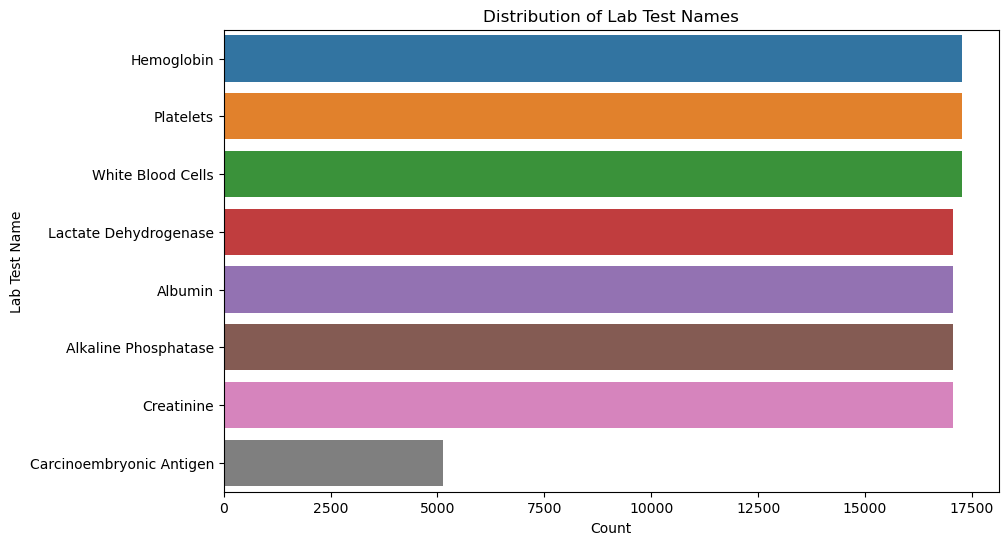

In [11]:
plt.figure(figsize=(10, 6))
sns.countplot(y='LBTEST', data=df1, order=df1['LBTEST'].value_counts().index)
plt.title('Distribution of Lab Test Names')
plt.xlabel('Count')
plt.ylabel('Lab Test Name')
plt.show()

# Distribution of Baseline indicator (LBBASE)


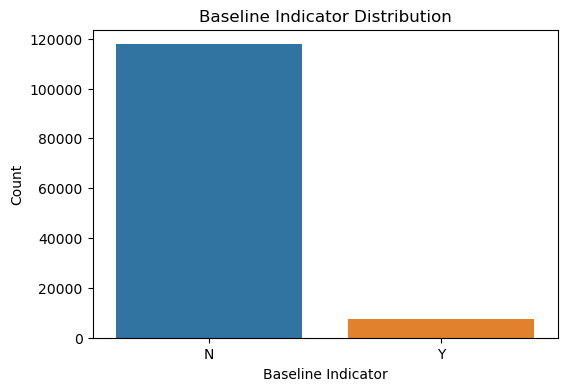

In [12]:
plt.figure(figsize=(6, 4))
sns.countplot(x='LBBASE', data=df1)
plt.title('Baseline Indicator Distribution')
plt.xlabel('Baseline Indicator')
plt.ylabel('Count')
plt.show()

# Summary statistics for LBSTRESN grouped by LBTEST


In [13]:
print(df1.groupby('LBTEST')['LBSTRESN'].describe())

                            count        mean          std    min    25%  \
LBTEST                                                                     
Albumin                   16099.0   38.391453     8.117744   3.20   35.0   
Alkaline Phosphatase      16513.0  173.934932   164.427237   1.28   90.0   
Carcinoembryonic Antigen   4726.0  239.361555  1756.866958   0.12    3.2   
Creatinine                16889.0   73.711980    64.948397  17.68   60.0   
Hemoglobin                17249.0  124.127083    22.013960  59.00  113.0   
Lactate Dehydrogenase     15915.0  421.530376   428.388529   1.32  208.0   
Platelets                 17236.0  196.018781    99.779644   2.20  125.0   
White Blood Cells         17249.0    7.991077   177.974129   0.49    4.3   

                              50%      75%        max  
LBTEST                                                 
Albumin                    39.000   42.000    410.000  
Alkaline Phosphatase      122.000  194.000   2565.000  
Carcinoembryoni

# Distribution of LBSTRESN values for each LBTEST

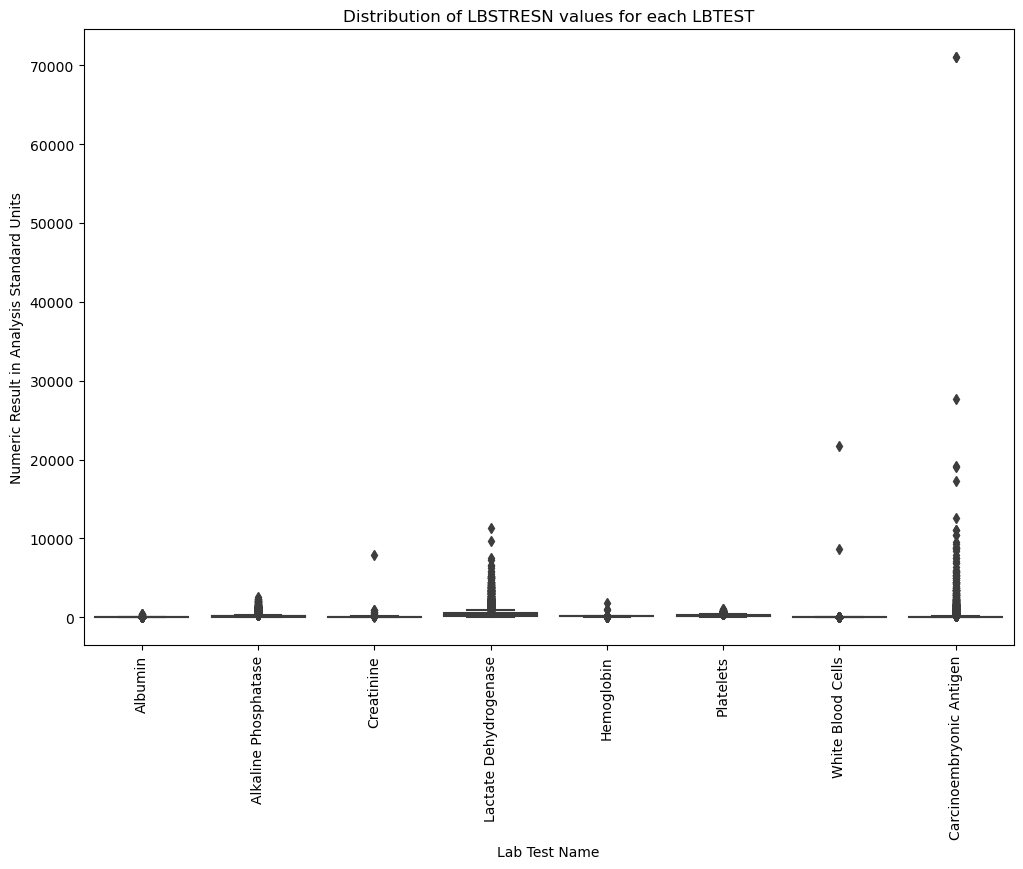

In [14]:
plt.figure(figsize=(12, 8))
sns.boxplot(x='LBTEST', y='LBSTRESN', data=df1)
plt.xticks(rotation=90)
plt.title('Distribution of LBSTRESN values for each LBTEST')
plt.xlabel('Lab Test Name')
plt.ylabel('Numeric Result in Analysis Standard Units')
plt.show()


#  Scatter plot of LBSTRESN vs. VISITDY


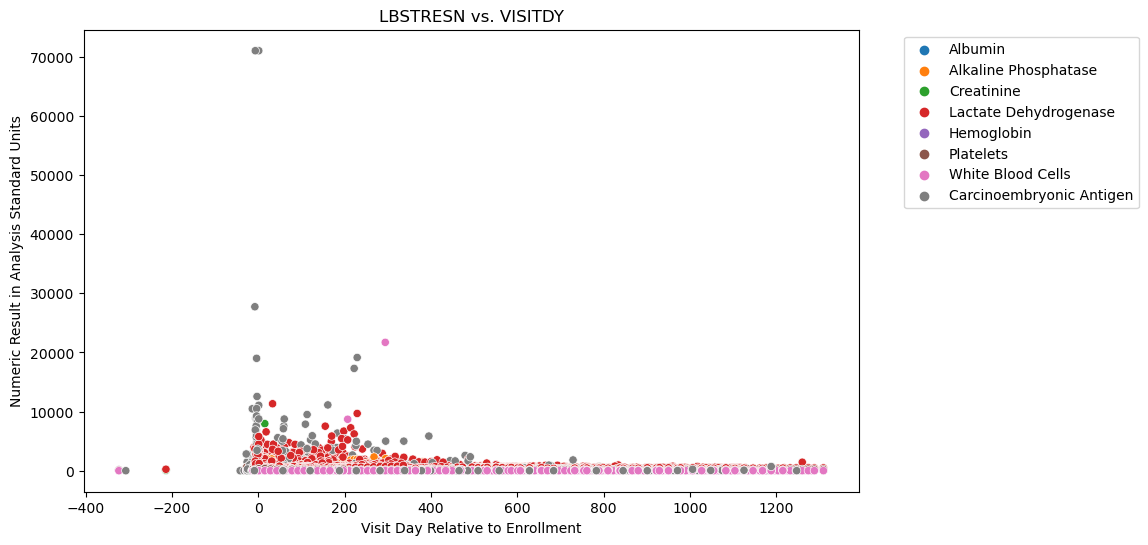

In [15]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='VISITDY', y='LBSTRESN', hue='LBTEST', data=df1)
plt.title('LBSTRESN vs. VISITDY')
plt.xlabel('Visit Day Relative to Enrollment')
plt.ylabel('Numeric Result in Analysis Standard Units')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

# Summary statistics for LBSTRESN by Visit (VISIT)


In [16]:
print("\nSummary statistics for LBSTRESN by Visit:")
print(df1.groupby('VISIT')['LBSTRESN'].describe())


Summary statistics for LBSTRESN by Visit:
                  count        mean         std    min     25%    50%     75%  \
VISIT                                                                           
C56                 1.0   68.000000         NaN  68.00  68.000   68.0   68.00   
CMNT3               7.0  178.601143  157.517466   6.10  58.554  121.0  289.50   
Cycle 1, day 1   6231.0  196.425833  342.071607   1.52  42.000  106.0  237.50   
Cycle 10, day 1  4996.0  137.899643  210.308202   1.50  41.000  101.0  150.00   
Cycle 11, day 1  4731.0  138.523070  198.500637   1.30  41.000  101.0  150.65   
...                 ...         ...         ...    ...     ...    ...     ...   
Week 72            66.0   63.007424  293.884028   0.50   2.100    3.8   12.35   
Week 8            822.0  207.205511  713.592892   0.25   4.500   15.0   86.59   
Week 80            51.0   26.540980   83.245293   1.00   2.100    3.4    7.30   
Week 88            39.0   34.875795  112.042929   0.80   1.750    

#  Heatmap of correlation matrix


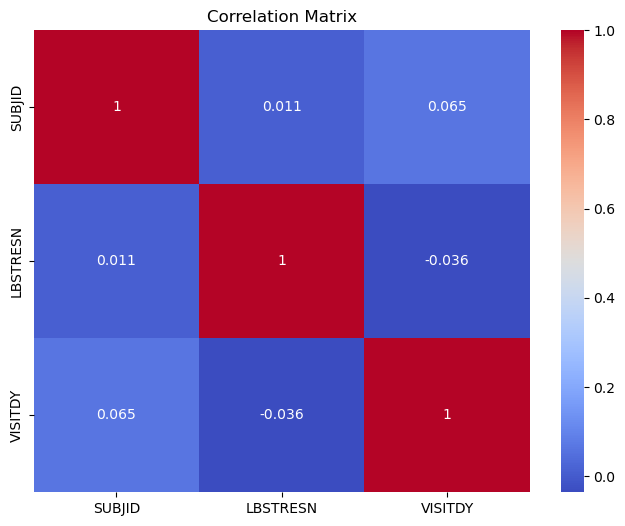

In [17]:
numeric_df = df1.select_dtypes(include=['number'])
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()


 # Compare baseline and post-baseline values for a specific test

In [18]:
col1=df1['LBTEST'].unique()

In [19]:
df1.head()

,SUBJID,LBTEST,LBBASE,LBSTRESN,LBSTUNIT,VISITDY,VISIT
0,1,Albumin,N,32.0,g/L,-6.0,Screening
1,1,Albumin,Y,30.0,g/L,3.0,"Cycle 1, day 1"
2,1,Albumin,N,31.0,g/L,17.0,"Cycle 2, day 1"
3,1,Albumin,N,29.0,g/L,31.0,"Cycle 3, day 1"
4,1,Albumin,N,30.0,g/L,45.0,"Cycle 4, day 1"


Albumin


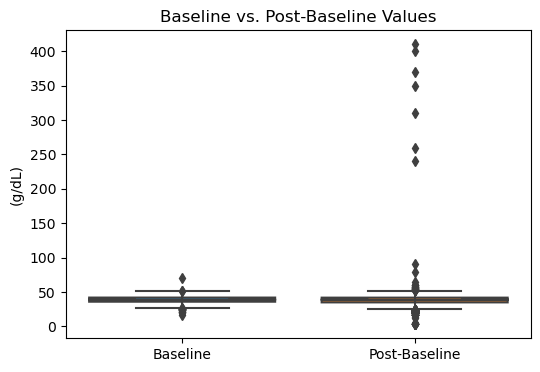

Alkaline Phosphatase


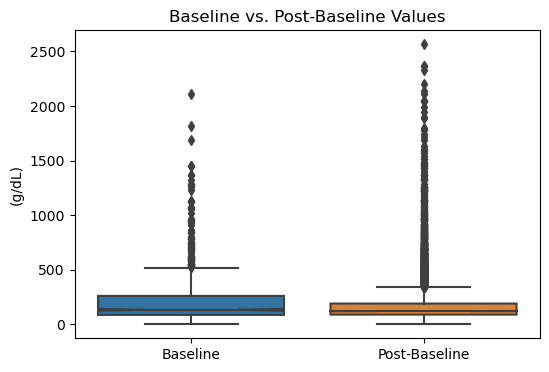

Creatinine


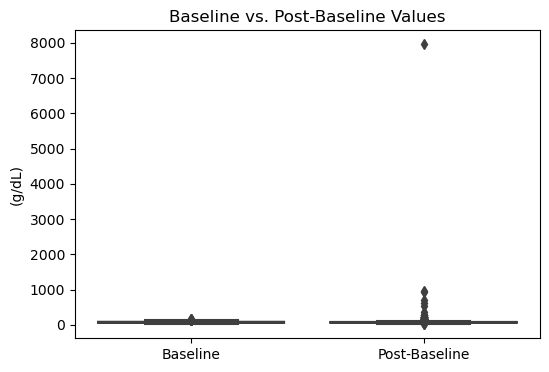

Lactate Dehydrogenase


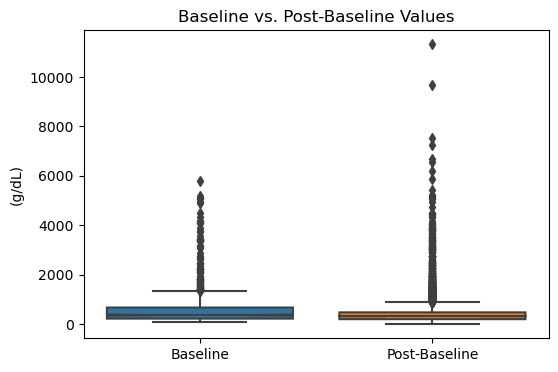

Hemoglobin


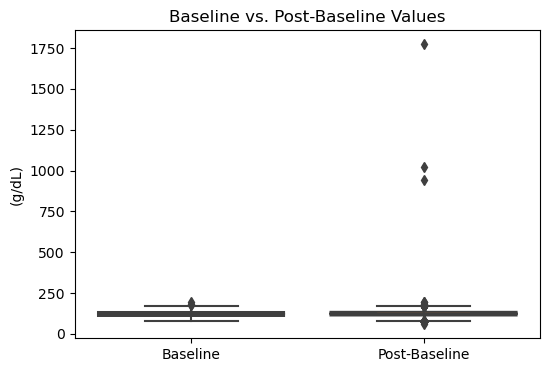

Platelets


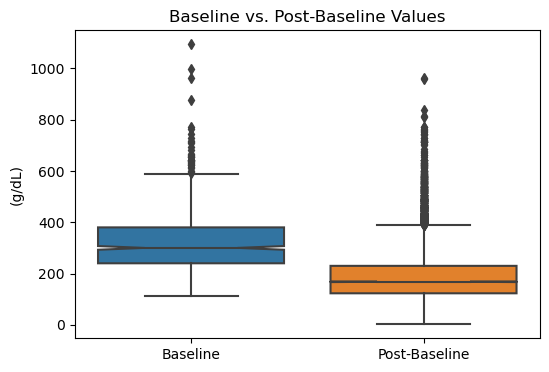

White Blood Cells


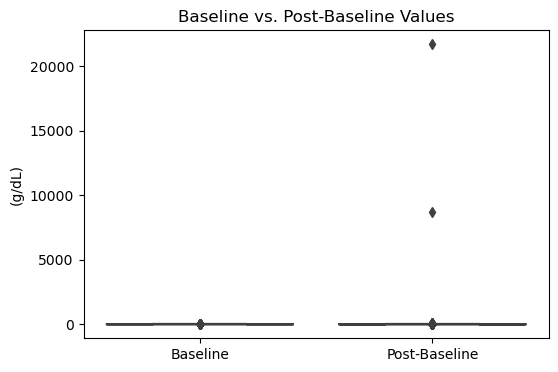

Carcinoembryonic Antigen


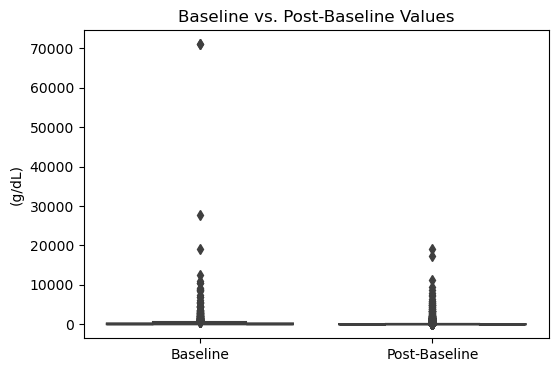

In [20]:
for i in col1:
    al_df=df1[df1['LBTEST']==i]
    baseline_values=al_df[al_df['LBBASE']=='Y']['LBSTRESN']
    post_baseline_values = al_df[al_df['LBBASE'] == 'N']['LBSTRESN']
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=[baseline_values, post_baseline_values], notch=True)
    plt.xticks([0, 1], ['Baseline', 'Post-Baseline'])
    print(i)
    plt.title('Baseline vs. Post-Baseline Values')
    plt.ylabel('(g/dL)')
    plt.show()

pip install pandas matplotlib seaborn scikit-learn

# Principal Component Analysis

In [21]:
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

numeric_cols = df1.select_dtypes(include=['number']).columns
numeric_df1 = df1[numeric_cols].dropna()  

scaler = StandardScaler()
scaled_data = scaler.fit_transform(numeric_df1)

In [22]:
# Perform PCA
pca = PCA(n_components=2)  
principal_components = pca.fit_transform(scaled_data)

pca_df1 = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'])

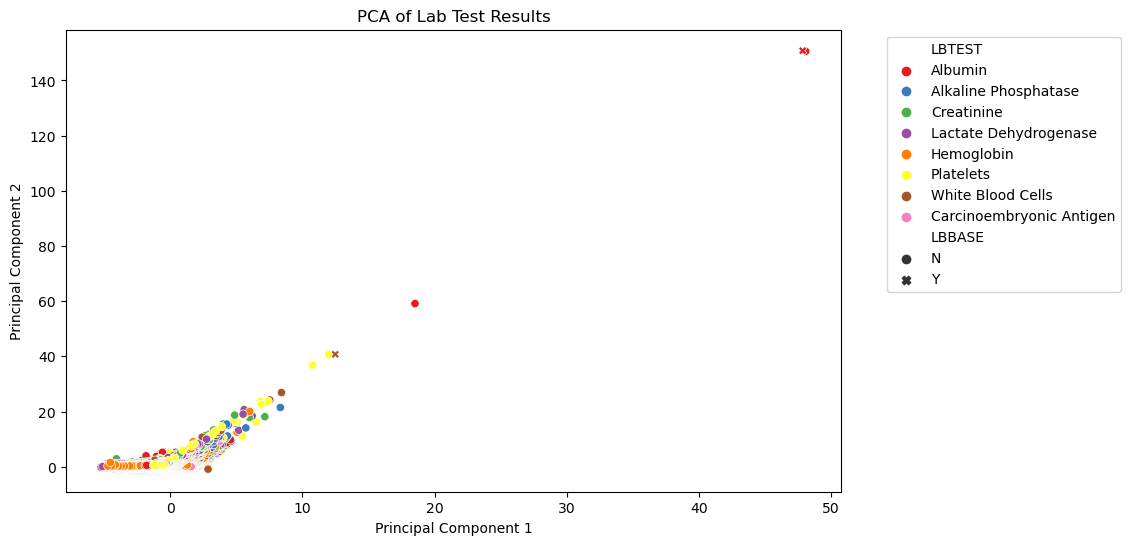

In [23]:
pca_df1['LBTEST'] = df1.loc[numeric_df1.index, 'LBTEST']
pca_df1['LBBASE'] = df1.loc[numeric_df1.index, 'LBBASE']

# Plot the PCA results
plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='LBTEST', style='LBBASE', data=pca_df1, palette='Set1')
plt.title('PCA of Lab Test Results')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

In [24]:
# Explained variance
print("\nExplained variance ratio by each principal component:")
print(pca.explained_variance_ratio_)


Explained variance ratio by each principal component:
[0.3561286  0.33651838]


# Correlation Tests

In [26]:
from scipy.stats import pearsonr, spearmanr, kendalltau, pointbiserialr
numerical_df = df1.select_dtypes(include=['number'])
categorical_df = df1.select_dtypes(exclude=['number'])

In [27]:
numeric_cols = df1.select_dtypes(include=['number']).columns
numeric_df1 = df1[numeric_cols].dropna()  
df_bi = df1.dropna()

# Pearson correlation
pearson_corr = numeric_df1.corr(method='pearson')

# Spearman correlation
spearman_corr = numeric_df1.corr(method='spearman')

# Kendall correlation
kendall_corr = numeric_df1.corr(method='kendall')

# Point-biserial correlation for binary variables
if 'LBBASE' in df1.columns and 'LBSTRESN' in df1.columns:
    binary_col = df_bi['LBBASE'].map({'Y': 1, 'N': 0})
    numeric_col = df_bi['LBSTRESN']
    point_biserial_corr, _ = pointbiserialr(binary_col, numeric_col)
else:
    point_biserial_corr = None

In [28]:
print("\nPearson Correlation Matrix:")
print(pearson_corr)

print("\nSpearman Correlation Matrix:")
print(spearman_corr)

print("\nKendall Correlation Matrix:")
print(kendall_corr)

if point_biserial_corr is not None:
    print("\nPoint-biserial Correlation between LBBASE and LBSTRESN:")
    print(point_biserial_corr)



Pearson Correlation Matrix:
            SUBJID  LBSTRESN   VISITDY
SUBJID    1.000000  0.011216  0.063327
LBSTRESN  0.011216  1.000000 -0.035851
VISITDY   0.063327 -0.035851  1.000000

Spearman Correlation Matrix:
            SUBJID  LBSTRESN   VISITDY
SUBJID    1.000000  0.008298  0.032637
LBSTRESN  0.008298  1.000000 -0.047672
VISITDY   0.032637 -0.047672  1.000000

Kendall Correlation Matrix:
            SUBJID  LBSTRESN   VISITDY
SUBJID    1.000000  0.005522  0.021991
LBSTRESN  0.005522  1.000000 -0.031988
VISITDY   0.021991 -0.031988  1.000000

Point-biserial Correlation between LBBASE and LBSTRESN:
0.06498753045390326


Text(0.5, 1.0, 'Pearson Correlation')

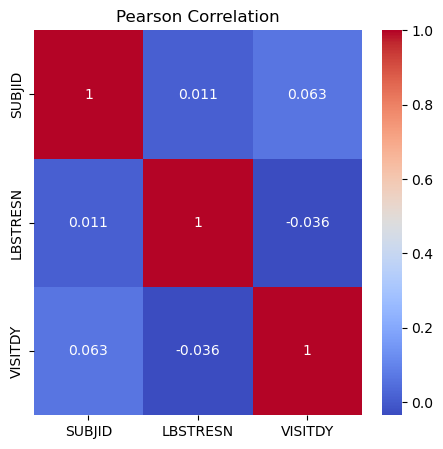

In [29]:
# Heatmap of correlation matrices
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
sns.heatmap(pearson_corr, annot=True, cmap='coolwarm')
plt.title('Pearson Correlation')


Text(0.5, 1.0, 'Spearman Correlation')

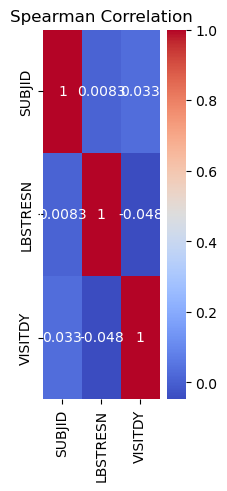

In [30]:
plt.subplot(1, 3, 2)
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm')
plt.title('Spearman Correlation')

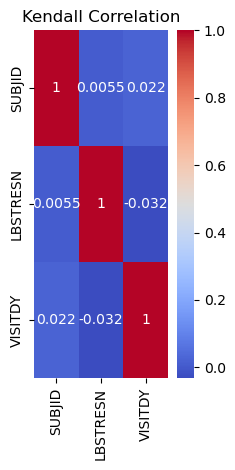

In [31]:
plt.subplot(1, 3, 3)
sns.heatmap(kendall_corr, annot=True, cmap='coolwarm')
plt.title('Kendall Correlation')

plt.tight_layout()
plt.show()

# Statistical Tests

In [32]:
from scipy.stats import ttest_ind, chi2_contingency, f_oneway, pearsonr, spearmanr, kendalltau, pointbiserialr
import statsmodels.api as sm
from statsmodels.formula.api import ols

# T-test: Compare LBSTRESN between two groups (e.g., baseline vs. post-baseline)
baseline_values = df1[df1['LBBASE'] == 'Y']['LBSTRESN']
post_baseline_values = df1[df1['LBBASE'] == 'N']['LBSTRESN']
t_stat, t_pvalue = ttest_ind(baseline_values, post_baseline_values)
print(f"T-test between baseline and post-baseline LBSTRESN: t-statistic = {t_stat}, p-value = {t_pvalue}")

T-test between baseline and post-baseline LBSTRESN: t-statistic = nan, p-value = nan


In [33]:
for i in col1:
    al_df=df1[df1['LBTEST']==i]
    baseline_values=al_df[al_df['LBBASE']=='Y']['LBSTRESN']
    post_baseline_values = al_df[al_df['LBBASE'] == 'N']['LBSTRESN']
    t_stat, t_pvalue = ttest_ind(baseline_values, post_baseline_values)
    print(f"T-test between baseline and post-baseline LBSTRESN: t-statistic = {t_stat}, p-value = {t_pvalue}")

T-test between baseline and post-baseline LBSTRESN: t-statistic = nan, p-value = nan
T-test between baseline and post-baseline LBSTRESN: t-statistic = nan, p-value = nan
T-test between baseline and post-baseline LBSTRESN: t-statistic = nan, p-value = nan
T-test between baseline and post-baseline LBSTRESN: t-statistic = nan, p-value = nan
T-test between baseline and post-baseline LBSTRESN: t-statistic = nan, p-value = nan
T-test between baseline and post-baseline LBSTRESN: t-statistic = nan, p-value = nan
T-test between baseline and post-baseline LBSTRESN: t-statistic = nan, p-value = nan
T-test between baseline and post-baseline LBSTRESN: t-statistic = nan, p-value = nan


In [34]:
# Chi-square test: Association between categorical variables (e.g., LBBASE and VISIT)
contingency_table = pd.crosstab(df1['LBBASE'], df1['VISIT'])
chi2_stat, chi2_pvalue, dof, ex = chi2_contingency(contingency_table)
print(f"Chi-square test between LBBASE and VISIT: chi2-statistic = {chi2_stat}, p-value = {chi2_pvalue}")

# ANOVA: Compare LBSTRESN across different VISIT groups
anova_model = ols('LBSTRESN ~ C(VISIT)', data=df1).fit()
anova_table = sm.stats.anova_lm(anova_model, typ=2)
print("\nANOVA table for LBSTRESN across VISIT groups:")
print(anova_table)

Chi-square test between LBBASE and VISIT: chi2-statistic = 104264.36137409713, p-value = 0.0

ANOVA table for LBSTRESN across VISIT groups:
                sum_sq        df         F        PR(>F)
C(VISIT)  1.277677e+08     114.0  6.644846  3.047194e-95
Residual  2.053712e+10  121761.0       NaN           NaN


# Basic Regression

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [37]:
df1.head()

,SUBJID,LBTEST,LBBASE,LBSTRESN,LBSTUNIT,VISITDY,VISIT
0,1,Albumin,N,32.0,g/L,-6.0,Screening
1,1,Albumin,Y,30.0,g/L,3.0,"Cycle 1, day 1"
2,1,Albumin,N,31.0,g/L,17.0,"Cycle 2, day 1"
3,1,Albumin,N,29.0,g/L,31.0,"Cycle 3, day 1"
4,1,Albumin,N,30.0,g/L,45.0,"Cycle 4, day 1"


In [38]:
label_encoder = LabelEncoder()
df1['LBBASE'] = label_encoder.fit_transform(df1['LBBASE'])
df1['LBSTUNIT'] = label_encoder.fit_transform(df1['LBSTUNIT'])

In [39]:
X = df1[['SUBJID', 'LBBASE', 'LBSTUNIT', 'VISITDY']]
y = df1['LBSTRESN']

In [40]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [41]:
# Train the regression model
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [42]:
y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error: {mse}')
print(f'R^2 Score: {r2}')

Mean Squared Error: 312103.91195813636
R^2 Score: 0.005345261037343785


# adls_pds2019

In [43]:
df2.shape

(29118, 11)

In [44]:
df2.head()

,SUBJID,VISITDY,VISIT,LSCAT,LSNEW,LSSLD,LSLD,LSSITE,LSNEWANY,LSREADER,LSTYPE
0,1,-28.0,Screening,Target lesion,N,426.0,168.0,Liver,N,Radiologist 1,Central
1,1,-28.0,Screening,Target lesion,N,426.0,80.0,Liver,N,Radiologist 1,Central
2,1,-28.0,Screening,Target lesion,N,426.0,55.0,Liver,N,Radiologist 1,Central
3,1,-28.0,Screening,Target lesion,N,426.0,71.0,Liver,N,Radiologist 1,Central
4,1,-28.0,Screening,Target lesion,N,426.0,52.0,Liver,N,Radiologist 1,Central


In [45]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29118 entries, 0 to 29117
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SUBJID    29118 non-null  int64  
 1   VISITDY   29118 non-null  float64
 2   VISIT     29118 non-null  object 
 3   LSCAT     29118 non-null  object 
 4   LSNEW     29118 non-null  object 
 5   LSSLD     16930 non-null  float64
 6   LSLD      17461 non-null  float64
 7   LSSITE    28850 non-null  object 
 8   LSNEWANY  29118 non-null  object 
 9   LSREADER  29118 non-null  object 
 10  LSTYPE    29118 non-null  object 
dtypes: float64(3), int64(1), object(7)
memory usage: 2.4+ MB


In [46]:
df2.describe()

,SUBJID,VISITDY,LSSLD,LSLD
count,29118.000000,29118.000000,16930.000000,17461.000000
mean,600.580157,177.064256,132.336267,30.003665
std,338.793316,191.739023,101.185453,23.323682
min,1.000000,-42.000000,0.000000,0.000000
25%,317.000000,54.000000,56.250000,14.000000
50%,619.000000,119.000000,106.000000,24.000000
75%,880.000000,243.000000,183.000000,39.000000
max,1181.000000,1323.000000,644.000000,191.000000


In [47]:
df2.nunique()

SUBJID      521
VISITDY     577
VISIT        44
LSCAT         3
LSNEW         2
LSSLD       428
LSLD        165
LSSITE       15
LSNEWANY      2
LSREADER      3
LSTYPE        1
dtype: int64

# Heatmap of Correlation Matrix

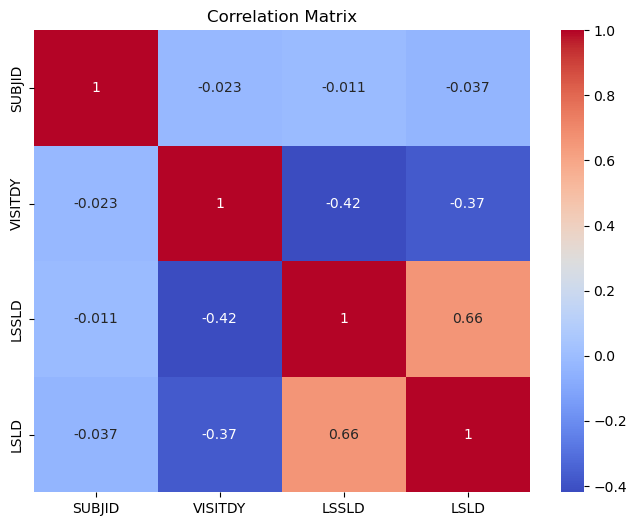

In [48]:
numeric_df = df2.select_dtypes(include=['number'])
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

# Increase or Decrease in Tumour Size

In [49]:
df2_sorted = df2.sort_values(by=['SUBJID', 'LSSITE', 'VISITDY'])

# Calculate the size change and percentage change
df2_sorted['Size Change'] = df2_sorted.groupby(['SUBJID', 'LSSITE'])['LSLD'].diff()
df2_sorted['Percentage Change'] = df2_sorted.groupby(['SUBJID', 'LSSITE'])['LSLD'].pct_change() * 100

df2_sorted[['SUBJID', 'LSSITE', 'VISITDY', 'LSLD', 'Size Change', 'Percentage Change']]

,SUBJID,LSSITE,VISITDY,LSLD,Size Change,Percentage Change
12,1,Gastrointestinal,-3.0,NaN,NaN,NaN
26,1,Gastrointestinal,57.0,NaN,NaN,NaN
0,1,Liver,-28.0,168.0,NaN,NaN
1,1,Liver,-28.0,80.0,-88.0,-52.380952
2,1,Liver,-28.0,55.0,-25.0,-31.250000
...,...,...,...,...,...,...
29117,1181,Skin,185.0,NaN,NaN,NaN
29092,1181,NaN,-6.0,NaN,NaN,NaN
29100,1181,NaN,60.0,NaN,NaN,NaN
29108,1181,NaN,123.0,NaN,NaN,NaN


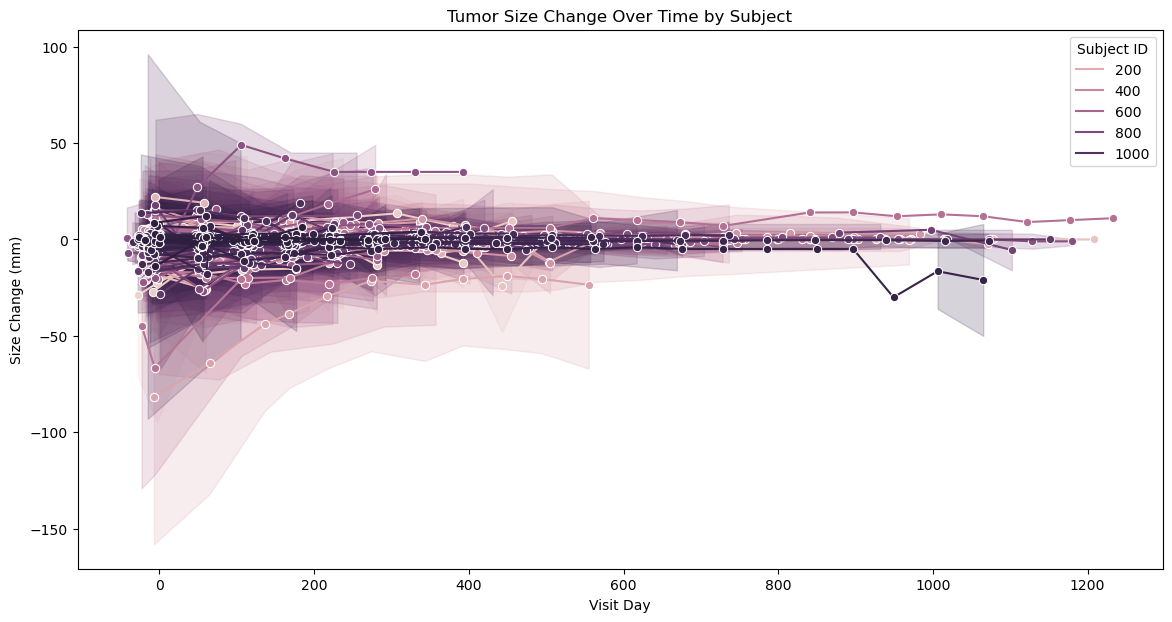

In [50]:
# Visualization for size change
plt.figure(figsize=(14, 7))
sns.lineplot(data=df2_sorted, x='VISITDY', y='Size Change', hue='SUBJID', marker='o')
plt.title('Tumor Size Change Over Time by Subject')
plt.xlabel('Visit Day')
plt.ylabel('Size Change (mm)')
plt.legend(title='Subject ID')
plt.show()

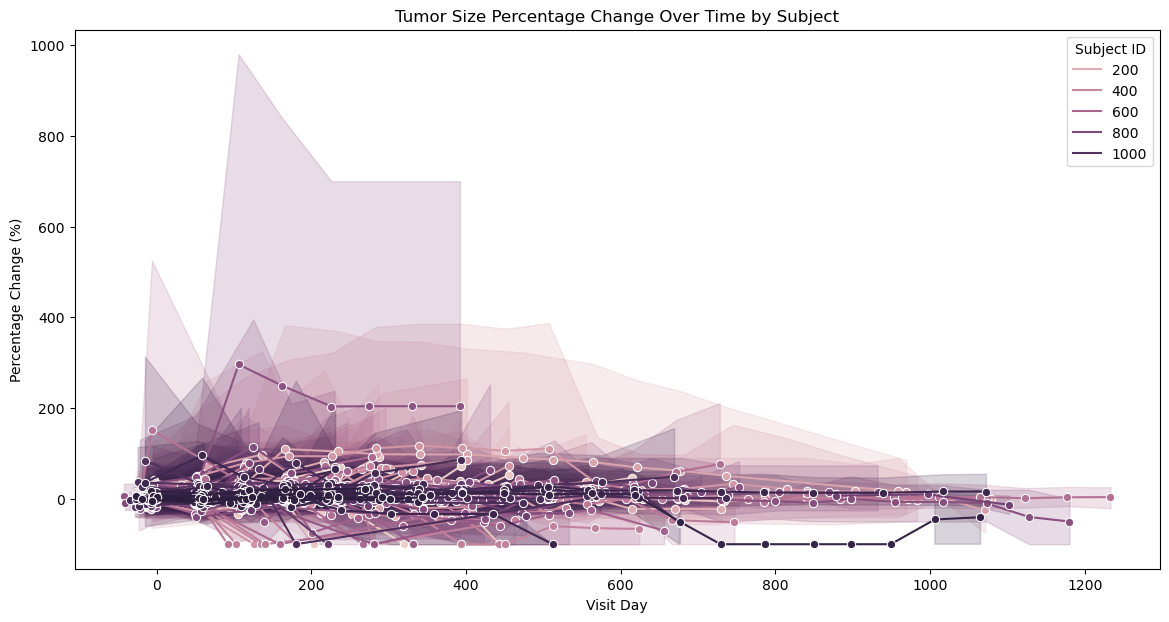

In [51]:
# Visualization for percentage change
plt.figure(figsize=(14, 7))
sns.lineplot(data=df2_sorted, x='VISITDY', y='Percentage Change', hue='SUBJID', marker='o')
plt.title('Tumor Size Percentage Change Over Time by Subject')
plt.xlabel('Visit Day')
plt.ylabel('Percentage Change (%)')
plt.legend(title='Subject ID')
plt.show()

# Correlation Tests

In [52]:
from scipy.stats import pearsonr, spearmanr, kendalltau, pointbiserialr
numeric_cols = df2.select_dtypes(include=['number']).columns
numeric_df2 = df2[numeric_cols].dropna()  
df_bi = df2.dropna()

# Pearson correlation
pearson_corr = numeric_df2.corr(method='pearson')

# Spearman correlation
spearman_corr = numeric_df2.corr(method='spearman')

# Kendall correlation
kendall_corr = numeric_df2.corr(method='kendall')

In [53]:
print("\nPearson Correlation Matrix:")
print(pearson_corr)

print("\nSpearman Correlation Matrix:")
print(spearman_corr)

print("\nKendall Correlation Matrix:")
print(kendall_corr)

if point_biserial_corr is not None:
    print("\nPoint-biserial Correlation between LBBASE and LBSTRESN:")
    print(point_biserial_corr)


Pearson Correlation Matrix:
           SUBJID   VISITDY     LSSLD      LSLD
SUBJID   1.000000 -0.006973 -0.010904 -0.038863
VISITDY -0.006973  1.000000 -0.419900 -0.380788
LSSLD   -0.010904 -0.419900  1.000000  0.660313
LSLD    -0.038863 -0.380788  0.660313  1.000000

Spearman Correlation Matrix:
           SUBJID   VISITDY     LSSLD      LSLD
SUBJID   1.000000 -0.036528  0.005022 -0.028041
VISITDY -0.036528  1.000000 -0.491280 -0.504081
LSSLD    0.005022 -0.491280  1.000000  0.701488
LSLD    -0.028041 -0.504081  0.701488  1.000000

Kendall Correlation Matrix:
           SUBJID   VISITDY     LSSLD      LSLD
SUBJID   1.000000 -0.024240  0.004455 -0.018851
VISITDY -0.024240  1.000000 -0.341926 -0.353744
LSSLD    0.004455 -0.341926  1.000000  0.524410
LSLD    -0.018851 -0.353744  0.524410  1.000000

Point-biserial Correlation between LBBASE and LBSTRESN:
0.06498753045390326


In [54]:
(df2['LSSITE']).unique()

array(['Liver', 'Gastrointestinal', 'Lymph Nodes', 'Other', 'Pulmonary',
       'Abdomen', 'Central Nervous System', 'Pelvic Site', nan, 'Bone',
       'Skin', 'Spleen', 'Chest', 'Retroperitoneum', 'Musculoskeletal',
       'HEENT/Neck'], dtype=object)

Text(0.5, 1.0, 'Pearson Correlation')

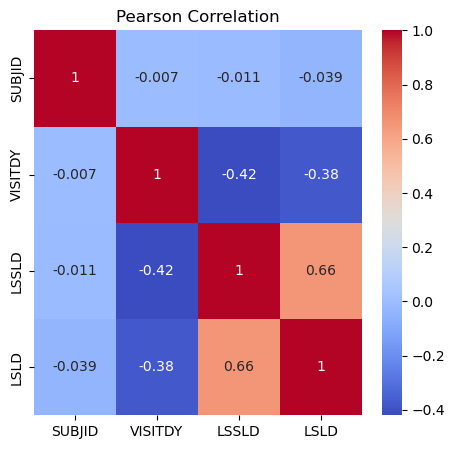

In [55]:
# Heatmap of correlation matrices
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
sns.heatmap(pearson_corr, annot=True, cmap='coolwarm')
plt.title('Pearson Correlation')

Text(0.5, 1.0, 'Spearmaan Correlation')

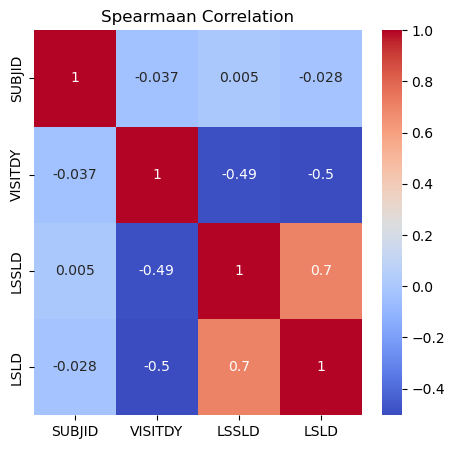

In [56]:
# Heatmap of correlation matrices
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm')
plt.title('Spearmaan Correlation')

Text(0.5, 1.0, 'Kendall Correlation')

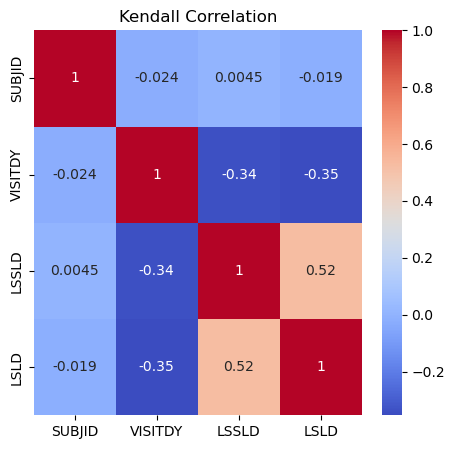

In [57]:
# Heatmap of correlation matrices
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
sns.heatmap(kendall_corr, annot=True, cmap='coolwarm')
plt.title('Kendall Correlation')

# Statistical Tests

In [58]:
df2['LSSITE_BINARY'] = (df2['LSSITE'] == 'Liver').astype(int)
group1 = df2[df2['LSSITE_BINARY'] == 1]['LSLD']
group2 = df2[df2['LSSITE_BINARY'] == 0]['LSLD']  # Hypothetical second group

# Perform T-Test 
# t_stat, p_val = ttest_ind(group1, group2)  # Uncomment when you have two groups

# Chi-Squared Test: Association between two categorical variables (LSNEW and LSNEWANY)
contingency_table = pd.crosstab(df2['LSNEW'], df2['LSNEWANY'])

# Perform Chi-Squared Test
chi2_stat, p_val_chi2, dof, expected = chi2_contingency(contingency_table)

# ANOVA: Compare LSLD across different VISITs
anova_result = f_oneway(
    df2[df2['VISIT'] == 'Screening']['LSLD'],
    df2[df2['VISIT'] == 'Baseline']['LSLD'],
    df2[df2['VISIT'] == 'Week 4']['LSLD']
)

# print(f"T-Test: t-statistic = {t_stat}, p-value = {p_val}")  
print(f"Chi-Squared Test: chi2_stat = {chi2_stat}, p-value = {p_val_chi2}")
print(f"ANOVA: F-statistic = {anova_result.statistic}, p-value = {anova_result.pvalue}")

Chi-Squared Test: chi2_stat = 5970.411999204297, p-value = 0.0
ANOVA: F-statistic = nan, p-value = nan


# adrsp_2019

In [59]:
df3.head()

,SUBJID,RSRESP,VISITDY,VISIT,RSCONFYN,RSTRESP,RSNTRESP,RSNEW,RSREADER
0,1,NaN,-28.0,Screening,NaN,NaN,NaN,N,Radiologist 1
1,1,NaN,-28.0,Screening,NaN,NaN,NaN,N,Radiologist 2
2,1,NaN,-28.0,Screening,NaN,NaN,NaN,N,Oncologist
3,1,Stable disease,57.0,Week 8,NaN,Stable disease,Stable disease,N,Radiologist 1
4,1,Stable disease,57.0,Week 8,NaN,Stable disease,Stable disease,N,Radiologist 2


In [60]:
df3.shape

(10856, 9)

In [61]:
df3.nunique()

SUBJID      932
RSRESP        5
VISITDY     792
VISIT        46
RSCONFYN      2
RSTRESP       6
RSNTRESP      5
RSNEW         2
RSREADER      3
dtype: int64

In [62]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10856 entries, 0 to 10855
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SUBJID    10856 non-null  int64  
 1   RSRESP    8920 non-null   object 
 2   VISITDY   10856 non-null  float64
 3   VISIT     10856 non-null  object 
 4   RSCONFYN  2443 non-null   object 
 5   RSTRESP   8920 non-null   object 
 6   RSNTRESP  8920 non-null   object 
 7   RSNEW     10856 non-null  object 
 8   RSREADER  10856 non-null  object 
dtypes: float64(1), int64(1), object(7)
memory usage: 763.4+ KB


In [63]:
df3.describe()

,SUBJID,VISITDY
count,10856.000000,10856.000000
mean,591.016489,200.114499
std,338.809491,215.598660
min,1.000000,-43.000000
25%,304.000000,55.000000
50%,593.000000,135.000000
75%,869.000000,282.000000
max,1183.000000,1323.000000


In [64]:
df3.isnull().sum()

SUBJID         0
RSRESP      1936
VISITDY        0
VISIT          0
RSCONFYN    8413
RSTRESP     1936
RSNTRESP    1936
RSNEW          0
RSREADER       0
dtype: int64

# adsl_pds2019

In [65]:
df4.head()

,SUBJID,TRT,ATRT,PRSURG,DTHDY,DTH,PFSDYCR,PFSCR,LIVERMET,DIAGMONS,AGE,SEX,B_WEIGHT,B_HEIGHT,RACE,B_ECOG,HISSUBTY,B_METANM,DIAGTYPE
0,1,FOLFOX alone,FOLFOX alone,Y,558.0,1.0,558.0,1.0,Y,0.622951,64.0,Male,64.2,167.0,White or Caucasian,Symptoms but ambulatory,No sub-type,3.0,Colon
1,3,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,301.0,1.0,54.0,1.0,Y,1.868852,65.0,Male,67.0,165.0,White or Caucasian,Symptoms but ambulatory,No sub-type,5.0,Colon
2,4,FOLFOX alone,FOLFOX alone,Y,460.0,1.0,293.0,1.0,Y,1.213115,60.0,Male,75.0,175.0,White or Caucasian,Symptoms but ambulatory,No sub-type,1.0,Colon
3,5,FOLFOX alone,FOLFOX alone,Y,965.0,1.0,965.0,1.0,Y,2.196721,64.0,Female,52.0,160.0,White or Caucasian,Symptoms but ambulatory,Mucinous,2.0,Colon
4,6,FOLFOX alone,FOLFOX alone,N,211.0,1.0,56.0,1.0,Y,0.950820,74.0,Male,66.0,171.0,White or Caucasian,Fully active,Mucinous,1.0,Rectal


In [66]:
df4.shape

(935, 19)

In [67]:
df4.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 935 entries, 0 to 934
Data columns (total 19 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SUBJID    935 non-null    int64  
 1   TRT       935 non-null    object 
 2   ATRT      935 non-null    object 
 3   PRSURG    935 non-null    object 
 4   DTHDY     935 non-null    float64
 5   DTH       935 non-null    float64
 6   PFSDYCR   935 non-null    float64
 7   PFSCR     935 non-null    float64
 8   LIVERMET  935 non-null    object 
 9   DIAGMONS  924 non-null    float64
 10  AGE       935 non-null    float64
 11  SEX       935 non-null    object 
 12  B_WEIGHT  935 non-null    float64
 13  B_HEIGHT  934 non-null    float64
 14  RACE      935 non-null    object 
 15  B_ECOG    934 non-null    object 
 16  HISSUBTY  933 non-null    object 
 17  B_METANM  932 non-null    float64
 18  DIAGTYPE  935 non-null    object 
dtypes: float64(9), int64(1), object(9)
memory usage: 138.9+ KB


In [68]:
df4.describe()

,SUBJID,DTHDY,DTH,PFSDYCR,PFSCR,DIAGMONS,AGE,B_WEIGHT,B_HEIGHT,B_METANM
count,935.000000,935.000000,935.000000,935.000000,935.000000,924.000000,935.000000,935.000000,934.000000,932.000000
mean,596.189305,616.586096,0.737968,322.829947,0.867380,8.869811,60.976471,72.629230,167.411724,2.525751
std,341.194101,368.175348,0.439975,266.955762,0.339345,16.441764,10.590362,15.704801,9.312325,1.133601
min,1.000000,1.000000,0.000000,0.000000,0.000000,0.032787,27.000000,36.000000,134.000000,1.000000
25%,302.500000,295.000000,0.000000,146.000000,1.000000,1.245902,55.000000,62.000000,160.125000,2.000000
50%,602.000000,562.000000,1.000000,245.000000,1.000000,2.065574,62.000000,71.000000,168.000000,2.000000
75%,890.500000,953.000000,1.000000,409.500000,1.000000,5.868852,69.000000,82.000000,174.000000,3.000000
max,1183.000000,1403.000000,1.000000,1310.000000,1.000000,119.704918,85.000000,163.000000,197.000000,7.000000


# Eliminating unwanted columns

In [8]:
columns_to_drop = ['LBSTUNIT','VISIT']
df1= df1.drop(columns=columns_to_drop)
df1.shape

(125123, 5)

In [9]:
df1.head()

,SUBJID,LBTEST,LBBASE,LBSTRESN,VISITDY
0,1,Albumin,N,32.0,-6.0
1,1,Albumin,Y,30.0,3.0
2,1,Albumin,N,31.0,17.0
3,1,Albumin,N,29.0,31.0
4,1,Albumin,N,30.0,45.0


In [10]:
grouped = df1.groupby(['SUBJID', 'LBTEST','LBBASE'])['LBSTRESN'].mean().reset_index()
print(grouped)

       SUBJID                    LBTEST LBBASE     LBSTRESN
0           1                   Albumin      N    29.428571
1           1                   Albumin      Y    30.000000
2           1      Alkaline Phosphatase      N   306.714286
3           1      Alkaline Phosphatase      Y   435.000000
4           1  Carcinoembryonic Antigen      N  3106.000000
...       ...                       ...    ...          ...
14833    1183     Lactate Dehydrogenase      Y   240.600000
14834    1183                 Platelets      N   225.384615
14835    1183                 Platelets      Y   324.000000
14836    1183         White Blood Cells      N     4.994615
14837    1183         White Blood Cells      Y     6.850000

[14838 rows x 4 columns]


In [6]:
df1.shape

(125123, 5)

In [11]:
grouped.shape

(14838, 4)

In [7]:
df2.shape
columns_to_drop = ['LSREADER','VISIT','LSTYPE']
df2= df2.drop(columns=columns_to_drop)
df2.shape

(29118, 8)

In [8]:
df2.head()

,SUBJID,VISITDY,LSCAT,LSNEW,LSSLD,LSLD,LSSITE,LSNEWANY
0,1,-28.0,Target lesion,N,426.0,168.0,Liver,N
1,1,-28.0,Target lesion,N,426.0,80.0,Liver,N
2,1,-28.0,Target lesion,N,426.0,55.0,Liver,N
3,1,-28.0,Target lesion,N,426.0,71.0,Liver,N
4,1,-28.0,Target lesion,N,426.0,52.0,Liver,N


In [9]:
df3.shape

(10856, 9)

In [10]:
columns_to_drop = ['RSCONFYN','VISIT','RSREADER','RSRESP','RSTRESP','RSNTRESP']
df3= df3.drop(columns=columns_to_drop)
df3.shape

(10856, 3)

In [11]:
df3.head()

,SUBJID,VISITDY,RSNEW
0,1,-28.0,N
1,1,-28.0,N
2,1,-28.0,N
3,1,57.0,N
4,1,57.0,N


In [12]:
df4.shape

(935, 19)

In [13]:
df4.head()

,SUBJID,TRT,ATRT,PRSURG,DTHDY,DTH,PFSDYCR,PFSCR,LIVERMET,DIAGMONS,AGE,SEX,B_WEIGHT,B_HEIGHT,RACE,B_ECOG,HISSUBTY,B_METANM,DIAGTYPE
0,1,FOLFOX alone,FOLFOX alone,Y,558.0,1.0,558.0,1.0,Y,0.622951,64.0,Male,64.2,167.0,White or Caucasian,Symptoms but ambulatory,No sub-type,3.0,Colon
1,3,Panitumumab + FOLFOX,Panitumumab + FOLFOX,Y,301.0,1.0,54.0,1.0,Y,1.868852,65.0,Male,67.0,165.0,White or Caucasian,Symptoms but ambulatory,No sub-type,5.0,Colon
2,4,FOLFOX alone,FOLFOX alone,Y,460.0,1.0,293.0,1.0,Y,1.213115,60.0,Male,75.0,175.0,White or Caucasian,Symptoms but ambulatory,No sub-type,1.0,Colon
3,5,FOLFOX alone,FOLFOX alone,Y,965.0,1.0,965.0,1.0,Y,2.196721,64.0,Female,52.0,160.0,White or Caucasian,Symptoms but ambulatory,Mucinous,2.0,Colon
4,6,FOLFOX alone,FOLFOX alone,N,211.0,1.0,56.0,1.0,Y,0.950820,74.0,Male,66.0,171.0,White or Caucasian,Fully active,Mucinous,1.0,Rectal


In [14]:
columns_to_drop = ['TRT','ATRT','PRSURG','DTHDY','DTH','LIVERMET','DIAGMONS','AGE','SEX','B_WEIGHT','B_HEIGHT','RACE','B_ECOG','HISSUBTY','B_METANM','DIAGTYPE']
df4= df4.drop(columns=columns_to_drop)
df4.shape

(935, 3)

In [15]:
df4.head()

,SUBJID,PFSDYCR,PFSCR
0,1,558.0,1.0
1,3,54.0,1.0
2,4,293.0,1.0
3,5,965.0,1.0
4,6,56.0,1.0


In [16]:
df11=pd.merge(grouped,df2,on='SUBJID',how='inner')

In [17]:
df11.shape

(462699, 11)

In [18]:
df12=pd.merge(df11,df3,on='SUBJID',how='inner')

In [19]:
df12.shape

(9942707, 13)

In [20]:
df=pd.merge(df12,df4,on='SUBJID',how='inner')
df.shape

(9942707, 15)

In [21]:
df = df.drop_duplicates(keep='first')

In [22]:
df.shape

(2920450, 15)

# AE (Severity)

In [13]:
ae=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1183\\Data\\adae_pds2019.csv")

In [14]:
ae.shape

(3211, 7)

In [15]:
ae.head()

,SUBJID,AEPT,AESOC,AESTDYI,AEENDYI,AESEVCD,AECONT
0,3,Dermatitis acneiform,Skin and subcutaneous tissue disorders,12.0,29.0,1.0,N
1,3,Dermatitis acneiform,Skin and subcutaneous tissue disorders,41.0,57.0,1.0,N
2,7,Rash,Skin and subcutaneous tissue disorders,9.0,127.0,1.0,N
3,7,Rash,Skin and subcutaneous tissue disorders,128.0,141.0,2.0,N
4,7,Rash,Skin and subcutaneous tissue disorders,142.0,160.0,1.0,N


In [16]:
one_hot = pd.get_dummies(ae['AESEVCD'], prefix='Severity')

In [17]:
one_hot

,Severity_1.0,Severity_2.0,Severity_3.0,Severity_4.0
0,True,False,False,False
1,True,False,False,False
2,True,False,False,False
3,False,True,False,False
4,True,False,False,False
...,...,...,...,...
3206,False,True,False,False
3207,True,False,False,False
3208,True,False,False,False
3209,True,False,False,False


In [30]:
df_one_hot = ae[['SUBJID', 'AEPT', 'AECONT']].join(one_hot)

result = df_one_hot.groupby(['SUBJID', 'AEPT', 'AECONT']).sum().reset_index()

In [31]:
result.head()

,SUBJID,AEPT,AECONT,Severity_1.0,Severity_2.0,Severity_3.0,Severity_4.0
0,3,Dermatitis acneiform,N,2,0,0,0
1,7,Folliculitis,N,0,1,1,0
2,7,Furuncle,N,0,1,0,0
3,7,Rash,N,3,2,0,0
4,9,Dermatitis acneiform,N,1,0,0,0


In [32]:
result.shape

(1650, 7)

In [33]:
df=pd.merge(df,result,on='SUBJID',how='inner')

df.to_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1183\\Data\\1183_Final_Dataset.csv")

# EDA for Final Dataset

In [3]:
df=pd.read_csv("C:\\Users\\sdsek\\OneDrive\\Desktop\\Kolate.AI\\1183\\Data\\1183_Final_Dataset.csv")

In [4]:
df = df.drop(columns=['Unnamed: 0'])

In [5]:
df = df.drop_duplicates(keep='first')

In [6]:
df.shape

(7100293, 21)

In [7]:
df.head()

,SUBJID,LBTEST,LBBASE,LBSTRESN,VISITDY_x,LSCAT,LSNEW,LSSLD,LSLD,LSSITE,...,VISITDY_y,RSNEW,PFSDYCR,PFSCR,AEPT,AECONT,Severity_1.0,Severity_2.0,Severity_3.0,Severity_4.0
0,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,...,-11.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
1,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,...,55.0,Y,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
2,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,...,55.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
3,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,...,-11.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
4,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,...,55.0,Y,54.0,1.0,Dermatitis acneiform,N,2,0,0,0


In [8]:
df.tail()

,SUBJID,LBTEST,LBBASE,LBSTRESN,VISITDY_x,LSCAT,LSNEW,LSSLD,LSLD,LSSITE,...,VISITDY_y,RSNEW,PFSDYCR,PFSCR,AEPT,AECONT,Severity_1.0,Severity_2.0,Severity_3.0,Severity_4.0
7100288,1181,White Blood Cells,Y,9.0,185.0,Non-target lesion,N,NaN,NaN,Skin,...,185.0,N,184.0,1.0,Dry skin,Y,1,0,0,0
7100289,1181,White Blood Cells,Y,9.0,185.0,Non-target lesion,N,NaN,NaN,Skin,...,185.0,N,184.0,1.0,Pruritus,N,0,1,0,0
7100290,1181,White Blood Cells,Y,9.0,185.0,Non-target lesion,N,NaN,NaN,Skin,...,185.0,N,184.0,1.0,Skin fissures,N,1,0,0,0
7100291,1181,White Blood Cells,Y,9.0,185.0,Non-target lesion,N,NaN,NaN,Skin,...,185.0,N,184.0,1.0,Skin hyperpigmentation,N,1,1,0,0
7100292,1181,White Blood Cells,Y,9.0,185.0,Non-target lesion,N,NaN,NaN,Skin,...,185.0,N,184.0,1.0,Skin hyperpigmentation,Y,1,0,0,0


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7100293 entries, 0 to 7100292
Data columns (total 21 columns):
 #   Column        Dtype  
---  ------        -----  
 0   SUBJID        int64  
 1   LBTEST        object 
 2   LBBASE        object 
 3   LBSTRESN      float64
 4   VISITDY_x     float64
 5   LSCAT         object 
 6   LSNEW         object 
 7   LSSLD         float64
 8   LSLD          float64
 9   LSSITE        object 
 10  LSNEWANY      object 
 11  VISITDY_y     float64
 12  RSNEW         object 
 13  PFSDYCR       float64
 14  PFSCR         float64
 15  AEPT          object 
 16  AECONT        object 
 17  Severity_1.0  int64  
 18  Severity_2.0  int64  
 19  Severity_3.0  int64  
 20  Severity_4.0  int64  
dtypes: float64(7), int64(5), object(9)
memory usage: 1.1+ GB


In [43]:
df.describe()

,SUBJID,LBSTRESN,VISITDY_x,LSSLD,LSLD,VISITDY_y,PFSDYCR,PFSCR,Severity_1.0,Severity_2.0,Severity_3.0,Severity_4.0
count,7.100293e+06,7.095821e+06,7.100293e+06,4.356861e+06,4.485536e+06,7.100293e+06,7.100293e+06,7.100293e+06,7.100293e+06,7.100293e+06,7.100293e+06,7.100293e+06
mean,6.391293e+02,1.906939e+02,3.099304e+02,9.751444e+01,2.366560e+01,3.288947e+02,5.420251e+02,7.088815e-01,1.165979e+00,6.551351e-01,1.493854e-01,1.209190e-02
std,3.466572e+02,8.477098e+02,2.878854e+02,8.893327e+01,1.994760e+01,2.905059e+02,3.688802e+02,4.542781e-01,1.348112e+00,1.100278e+00,5.530536e-01,1.465373e-01
min,3.000000e+00,2.000000e-01,-4.200000e+01,0.000000e+00,0.000000e+00,-4.200000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.240000e+02,3.600000e+01,1.070000e+02,3.600000e+01,1.100000e+01,1.120000e+02,2.270000e+02,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,5.660000e+02,9.682500e+01,2.260000e+02,7.300000e+01,1.900000e+01,2.380000e+02,4.540000e+02,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,9.830000e+02,1.783704e+02,4.520000e+02,1.250000e+02,3.000000e+01,5.010000e+02,7.860000e+02,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
max,1.181000e+03,7.100000e+04,1.233000e+03,6.440000e+02,1.910000e+02,1.233000e+03,1.309000e+03,1.000000e+00,9.000000e+00,6.000000e+00,5.000000e+00,2.000000e+00


In [44]:
df.fillna(0, inplace=True)

In [45]:
df.columns

Index(['SUBJID', 'LBTEST', 'LBBASE', 'LBSTRESN', 'VISITDY_x', 'LSCAT', 'LSNEW',
       'LSSLD', 'LSLD', 'LSSITE', 'LSNEWANY', 'VISITDY_y', 'RSNEW', 'PFSDYCR',
       'PFSCR', 'AEPT', 'AECONT', 'Severity_1.0', 'Severity_2.0',
       'Severity_3.0', 'Severity_4.0'],
      dtype='object')

In [46]:
df.nunique()

SUBJID           335
LBTEST             8
LBBASE             2
LBSTRESN        3406
VISITDY_x        484
LSCAT              3
LSNEW              2
LSSLD            395
LSLD             156
LSSITE            15
LSNEWANY           2
VISITDY_y        484
RSNEW              2
PFSDYCR          235
PFSCR              2
AEPT              94
AECONT             2
Severity_1.0       9
Severity_2.0       7
Severity_3.0       5
Severity_4.0       3
dtype: int64

In [47]:
df.isnull().sum()

SUBJID          0
LBTEST          0
LBBASE          0
LBSTRESN        0
VISITDY_x       0
LSCAT           0
LSNEW           0
LSSLD           0
LSLD            0
LSSITE          0
LSNEWANY        0
VISITDY_y       0
RSNEW           0
PFSDYCR         0
PFSCR           0
AEPT            0
AECONT          0
Severity_1.0    0
Severity_2.0    0
Severity_3.0    0
Severity_4.0    0
dtype: int64

# Heatmap or Correlation Matrix

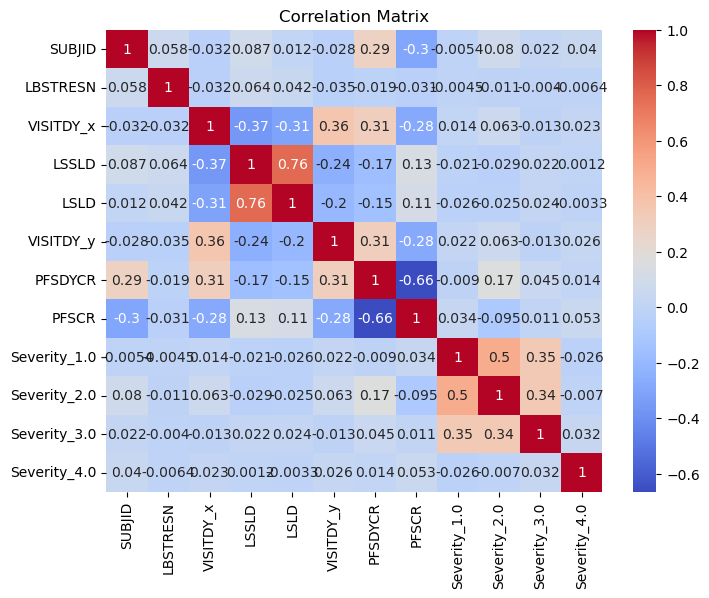

In [83]:
numeric_df = df.select_dtypes(include=['number'])
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

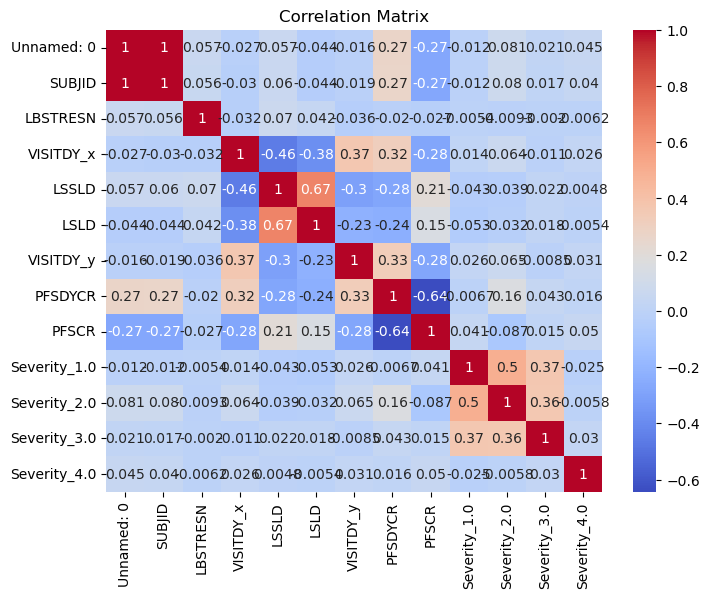

In [84]:
numeric_df = ae_df.select_dtypes(include=['number'])
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [85]:
for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')
correlation_matrix = df.corr()

In [86]:
correlation_matrix

,SUBJID,LBTEST,LBBASE,LBSTRESN,VISITDY_x,LSCAT,LSNEW,LSSLD,LSLD,LSSITE,...,VISITDY_y,RSNEW,PFSDYCR,PFSCR,AEPT,AECONT,Severity_1.0,Severity_2.0,Severity_3.0,Severity_4.0
SUBJID,1.000000,NaN,NaN,0.057584,-0.031791,NaN,NaN,0.086672,0.012383,NaN,...,-0.027550,NaN,0.288674,-0.295422,NaN,NaN,-0.005446,0.080357,0.021692,0.039576
LBTEST,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LBBASE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LBSTRESN,0.057584,NaN,NaN,1.000000,-0.031803,NaN,NaN,0.063639,0.042062,NaN,...,-0.034829,NaN,-0.019340,-0.031212,NaN,NaN,-0.004450,-0.010716,-0.004016,-0.006436
VISITDY_x,-0.031791,NaN,NaN,-0.031803,1.000000,NaN,NaN,-0.365078,-0.312344,NaN,...,0.364352,NaN,0.308654,-0.275737,NaN,NaN,0.013700,0.062757,-0.013229,0.023471
LSCAT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LSNEW,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LSSLD,0.086672,NaN,NaN,0.063639,-0.365078,NaN,NaN,1.000000,0.763551,NaN,...,-0.244476,NaN,-0.169280,0.134005,NaN,NaN,-0.020582,-0.028843,0.022161,0.001225
LSLD,0.012383,NaN,NaN,0.042062,-0.312344,NaN,NaN,0.763551,1.000000,NaN,...,-0.200112,NaN,-0.149049,0.113540,NaN,NaN,-0.026433,-0.025067,0.023825,-0.003346
LSSITE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# PCA

In [48]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt

In [53]:
numeric_columns = df.select_dtypes(include=['float64', 'int64']).columns

In [54]:
numeric_columns

Index(['SUBJID', 'LBSTRESN', 'VISITDY_x', 'LSSLD', 'LSLD', 'VISITDY_y',
       'PFSDYCR', 'PFSCR', 'Severity_1.0', 'Severity_2.0', 'Severity_3.0',
       'Severity_4.0'],
      dtype='object')

In [56]:
numerical_columns.shape

(7100293, 12)

In [59]:
scaler = StandardScaler()
numerical_df_standardized = scaler.fit_transform(numerical_columns)

In [60]:
pca = PCA(n_components=12)  
principal_components = pca.fit_transform(numerical_df_standardized)

In [61]:
pca

PCA(n_components=12)

In [62]:
pca_df = pd.DataFrame(data=principal_components, columns=[f'PC{i+1}' for i in range(12)]) 

In [63]:
explained_variance = pca.explained_variance_ratio_
print(f'Explained variance by each component: {explained_variance}')

Explained variance by each component: [0.21703016 0.15094181 0.13508688 0.08503319 0.08443673 0.07991559
 0.058346   0.05257515 0.05064874 0.03992012 0.02694967 0.01911597]


In [64]:
df_pca = pd.concat([df, pca_df], axis=1)

In [65]:
df_pca.head()

,SUBJID,LBTEST,LBBASE,LBSTRESN,VISITDY_x,LSCAT,LSNEW,LSSLD,LSLD,LSSITE,...,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12
0,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,...,-0.841058,-0.056288,-0.731433,0.354868,-0.001651,0.958789,0.622016,-0.811137,-0.323046,0.298788
1,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,...,-0.838512,-0.107531,-0.797390,0.451131,0.031405,0.802378,0.674755,-0.798357,-0.328989,0.295362
2,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,...,-0.838512,-0.107531,-0.797390,0.451131,0.031405,0.802378,0.674755,-0.798357,-0.328989,0.295362
3,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,...,-1.167679,0.065554,-0.546592,0.197166,-0.029562,0.951297,0.722799,-0.799706,-0.339668,0.610844
4,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,...,-1.165133,0.014310,-0.612549,0.293429,0.003494,0.794886,0.775539,-0.786926,-0.345611,0.607418


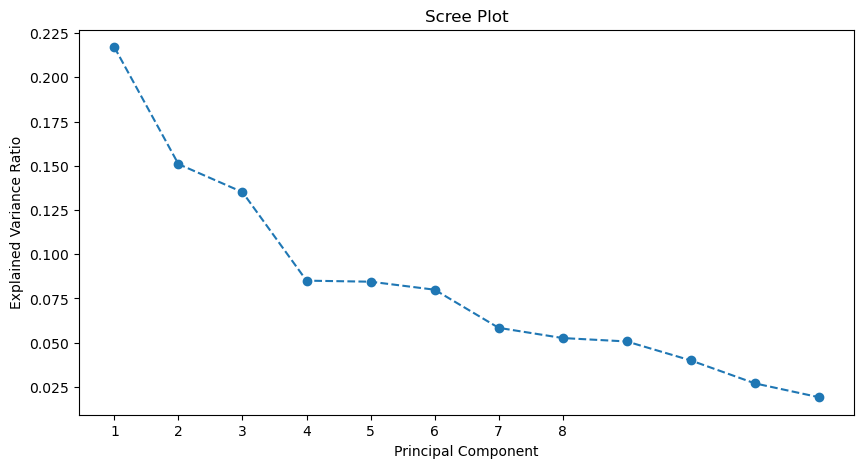

In [67]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, 13), explained_variance, marker='o', linestyle='--')
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.xticks(range(1, 9))
plt.show()

# Correlation Tests

# Numerical Vs Numerical Comparisons (Pearson,Spearman,Kendall Tests)

In [10]:
from scipy.stats import spearmanr, pearsonr, kendalltau
numeric_columns = df.select_dtypes(include=['float64', 'int64']).columns
categorical_columns=df.select_dtypes(include=['object']).columns

In [11]:
print(categorical_columns)
print(numeric_columns)

Index(['LBTEST', 'LBBASE', 'LSCAT', 'LSNEW', 'LSSITE', 'LSNEWANY', 'RSNEW',
       'AEPT', 'AECONT'],
      dtype='object')
Index(['SUBJID', 'LBSTRESN', 'VISITDY_x', 'LSSLD', 'LSLD', 'VISITDY_y',
       'PFSDYCR', 'PFSCR', 'Severity_1.0', 'Severity_2.0', 'Severity_3.0',
       'Severity_4.0'],
      dtype='object')


In [70]:
spearman_corr = df[numeric_columns].corr(method='spearman')
pearson_corr = df[numeric_columns].corr(method='pearson')
kendall_corr = df[numeric_columns].corr(method='kendall')

In [71]:
for col1 in numeric_columns:
    for col2 in numeric_columns:
        if col1 != col2:
            spearman_corr_val, spearman_p_val = spearmanr(df[col1], df[col2])
            print(f"Spearman correlation between {col1} and {col2}: {spearman_corr_val} (p-value: {spearman_p_val})")

Spearman correlation between SUBJID and LBSTRESN: 0.05889029135324064 (p-value: 0.0)
Spearman correlation between SUBJID and VISITDY_x: -0.03471574452506813 (p-value: 0.0)
Spearman correlation between SUBJID and LSSLD: 0.11790781623374022 (p-value: 0.0)
Spearman correlation between SUBJID and LSLD: 0.04147711628728573 (p-value: 0.0)
Spearman correlation between SUBJID and VISITDY_y: -0.031694359230883075 (p-value: 0.0)
Spearman correlation between SUBJID and PFSDYCR: 0.3449947093813721 (p-value: 0.0)
Spearman correlation between SUBJID and PFSCR: -0.3133192538756915 (p-value: 0.0)
Spearman correlation between SUBJID and Severity_1.0: -0.08511861122243036 (p-value: 0.0)
Spearman correlation between SUBJID and Severity_2.0: 0.07239449250401402 (p-value: 0.0)
Spearman correlation between SUBJID and Severity_3.0: 0.06605638096375897 (p-value: 0.0)
Spearman correlation between SUBJID and Severity_4.0: 0.03607301906455444 (p-value: 0.0)
Spearman correlation between LBSTRESN and SUBJID: 0.058

In [72]:
# Example of pairwise correlation using Pearson
for col1 in numeric_columns:
    for col2 in numeric_columns:
        if col1 != col2:
            pearson_corr_val, pearson_p_val = pearsonr(df[col1], df[col2])
            print(f"Pearson correlation between {col1} and {col2}: {pearson_corr_val} (p-value: {pearson_p_val})")
        else:
            print(f"Cannot calculate Pearson correlation between {col1} and {col2}: Insufficient data")

Cannot calculate Pearson correlation between SUBJID and SUBJID: Insufficient data
Pearson correlation between SUBJID and LBSTRESN: 0.05758362381980213 (p-value: 0.0)
Pearson correlation between SUBJID and VISITDY_x: -0.03179097359703025 (p-value: 0.0)
Pearson correlation between SUBJID and LSSLD: 0.08667221576731224 (p-value: 0.0)
Pearson correlation between SUBJID and LSLD: 0.012383151558885662 (p-value: 8.714597212127818e-239)
Pearson correlation between SUBJID and VISITDY_y: -0.027549622831921163 (p-value: 0.0)
Pearson correlation between SUBJID and PFSDYCR: 0.288673770490393 (p-value: 0.0)
Pearson correlation between SUBJID and PFSCR: -0.29542183989370385 (p-value: 0.0)
Pearson correlation between SUBJID and Severity_1.0: -0.005446155362015393 (p-value: 1.0151136377333337e-47)
Pearson correlation between SUBJID and Severity_2.0: 0.0803570704698266 (p-value: 0.0)
Pearson correlation between SUBJID and Severity_3.0: 0.021692155643523073 (p-value: 0.0)
Pearson correlation between SUBJ

In [73]:
for col1 in numeric_columns:
    for col2 in numeric_columns:
        if col1 != col2:
            kendall_corr_val, kendall_p_val = kendalltau(df[col1], df[col2])
            print(f"Kendall correlation between {col1} and {col2}: {kendall_corr_val} (p-value: {kendall_p_val})")

Kendall correlation between SUBJID and LBSTRESN: 0.040336473501647103 (p-value: 0.0)
Kendall correlation between SUBJID and VISITDY_x: -0.023446540073519918 (p-value: 0.0)
Kendall correlation between SUBJID and LSSLD: 0.08415950813755226 (p-value: 0.0)
Kendall correlation between SUBJID and LSLD: 0.02758660039295814 (p-value: 0.0)
Kendall correlation between SUBJID and VISITDY_y: -0.021366874015202895 (p-value: 0.0)
Kendall correlation between SUBJID and PFSDYCR: 0.23009163039366023 (p-value: 0.0)
Kendall correlation between SUBJID and PFSCR: -0.25981095320493236 (p-value: 0.0)
Kendall correlation between SUBJID and Severity_1.0: -0.06679959010809279 (p-value: 0.0)
Kendall correlation between SUBJID and Severity_2.0: 0.056776363438398175 (p-value: 0.0)
Kendall correlation between SUBJID and Severity_3.0: 0.052620190000770464 (p-value: 0.0)
Kendall correlation between SUBJID and Severity_4.0: 0.02971953778409703 (p-value: 0.0)
Kendall correlation between LBSTRESN and SUBJID: 0.040336473

# Categorical Vs Categorical Tests (Chi-Square Test)

In [80]:
from scipy.stats import chi2_contingency

from scipy import stats
print("\nStatistical tests for categorical vs. categorical columns:")
for col1 in categorical_columns:
    for col2 in categorical_columns:
        if col1 != col2:
            contingency_table = pd.crosstab(df[col1], df[col2])
            chi2_stat, chi2_p, _, _ = chi2_contingency(contingency_table)
            print(f"{col1} vs. {col2}: Chi-square statistic = {chi2_stat}, p-value = {chi2_p}")



Statistical tests for categorical vs. categorical columns:
LBTEST vs. LBBASE: Chi-square statistic = 125.4662544091741, p-value = 5.5576008332722386e-24
LBTEST vs. LSCAT: Chi-square statistic = 17.516635722815394, p-value = 0.22968972561094997
LBTEST vs. LSNEW: Chi-square statistic = 4.662586837007458, p-value = 0.7010609067527451
LBTEST vs. LSSITE: Chi-square statistic = 70.30363329064433, p-value = 0.9843896264215397
LBTEST vs. LSNEWANY: Chi-square statistic = 6.118652780853152, p-value = 0.5259653211384197
LBTEST vs. RSNEW: Chi-square statistic = 2.2257472774886136, p-value = 0.9462967518927335
LBTEST vs. AEPT: Chi-square statistic = 1288.0920522515642, p-value = 2.9888414962898375e-44
LBTEST vs. AECONT: Chi-square statistic = 32.21523570044926, p-value = 3.704876719063284e-05
LBBASE vs. LBTEST: Chi-square statistic = 125.4662544091741, p-value = 5.5576008332722386e-24
LBBASE vs. LSCAT: Chi-square statistic = 3.329057282357689, p-value = 0.1892798556879133
LBBASE vs. LSNEW: Chi-squ

# Numerical Vs Categorical Tests (t-test,ANOVA way)

In [ ]:
from scipy.stats import ttest_ind, f_oneway, chi2_contingency

print("\nStatistical tests for numerical vs. categorical columns:")
for col1 in numeric_columns:
    for col2 in categorical_columns:
        # t-test or ANOVA (if more than 2 categories)
        for category in df[col2].unique():
            group1 = df[df[col2] == category][col1]
            # Check if there are at least 2 groups with non-NaN values
            if len(group1.dropna()) >= 2:
                if len(df[col2].unique()) == 2:  # T-test
                    group2 = df[df[col2] != category][col1]
                    t_stat, t_p_value = ttest_ind(group1, group2)
                    print(f"{col1} for {col2}={category} vs. not {category}: T-statistic = {t_stat}, p-value = {t_p_value}")
                else:  # ANOVA
                    f_stat, f_p_value = f_oneway(*[df[df[col2] == cat][col1] for cat in df[col2].unique()])
                    print(f"{col1} across different categories of {col2}: F-statistic = {f_stat}, p-value = {f_p_value}")


Statistical tests for numerical vs. categorical columns:
SUBJID across different categories of LBTEST: F-statistic = 4.404783557312368, p-value = 6.672911613957442e-05
SUBJID across different categories of LBTEST: F-statistic = 4.404783557312368, p-value = 6.672911613957442e-05
SUBJID across different categories of LBTEST: F-statistic = 4.404783557312368, p-value = 6.672911613957442e-05
SUBJID across different categories of LBTEST: F-statistic = 4.404783557312368, p-value = 6.672911613957442e-05
SUBJID across different categories of LBTEST: F-statistic = 4.404783557312368, p-value = 6.672911613957442e-05
SUBJID across different categories of LBTEST: F-statistic = 4.404783557312368, p-value = 6.672911613957442e-05
SUBJID across different categories of LBTEST: F-statistic = 4.404783557312368, p-value = 6.672911613957442e-05
SUBJID across different categories of LBTEST: F-statistic = 4.404783557312368, p-value = 6.672911613957442e-05
SUBJID for LBBASE=N vs. not N: T-statistic = 2.3552016

# Basic Regresssion

# Linear Regression

In [84]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [88]:
numeric_columns=df[numeric_columns]

In [89]:
# Define dependent and independent variables
X = numeric_columns.drop(columns=['LBSTRESN'])
y = numeric_columns['LBSTRESN']

In [90]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [91]:
# Create a linear regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

LinearRegression()

In [92]:
y_pred = model.predict(X_test)

In [93]:
# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse}")

Mean Squared Error: 719092.7323248319


In [94]:
# Print model coefficients
print(f"Intercept: {model.intercept_}")
print(f"Coefficients: {model.coef_}")

Intercept: 286.9850302980842
Coefficients: [ 1.21445854e-01 -1.25857374e-02  6.06154088e-01 -4.83182401e-01
 -5.53715377e-02 -1.49956794e-01 -1.37651552e+02  2.59231011e+00
 -7.45480530e+00 -8.99148616e-01 -1.74260067e+01]


In [95]:
# To see which coefficient corresponds to which feature:
print(f"Feature names: {X.columns.tolist()}")

Feature names: ['SUBJID', 'VISITDY_x', 'LSSLD', 'LSLD', 'VISITDY_y', 'PFSDYCR', 'PFSCR', 'Severity_1.0', 'Severity_2.0', 'Severity_3.0', 'Severity_4.0']


In [96]:
y_pred

array([245.87422165, 312.07168039,  89.88599405, ..., 194.13726498,
       162.96756113,  69.18485255])

# Logistic Regression

In [97]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

In [99]:
df1=df

In [100]:
# Convert categorical variables to numeric using one-hot encoding or label encoding
df1['LBBASE'] = df1['LBBASE'].astype('category').cat.codes
df1['LSNEW'] = df1['LSNEW'].astype('category').cat.codes
df1['LSSITE'] = df1['LSSITE'].astype('category').cat.codes
df1['LSNEWANY'] = df1['LSNEWANY'].astype('category').cat.codes
df1['RSNEW'] = df1['RSNEW'].astype('category').cat.codes
df1['LSCAT']=df1['LSCAT'].astype('category').cat.codes

In [101]:
df1['RSNEW'] = df1['RSNEW'].astype('category').cat.codes

In [102]:
df1.head()

,SUBJID,LBTEST,LBBASE,LBSTRESN,VISITDY_x,LSCAT,LSNEW,LSSLD,LSLD,LSSITE,...,VISITDY_y,RSNEW,PFSDYCR,PFSCR,AEPT,AECONT,Severity_1.0,Severity_2.0,Severity_3.0,Severity_4.0
0,3,Albumin,0,36.84,-11.0,2,0,118.0,39.0,7,...,-11.0,0,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
1,3,Albumin,0,36.84,-11.0,2,0,118.0,39.0,7,...,55.0,1,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
2,3,Albumin,0,36.84,-11.0,2,0,118.0,39.0,7,...,55.0,0,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
3,3,Albumin,0,36.84,-11.0,2,0,65.0,35.0,7,...,-11.0,0,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
4,3,Albumin,0,36.84,-11.0,2,0,65.0,35.0,7,...,55.0,1,54.0,1.0,Dermatitis acneiform,N,2,0,0,0


In [103]:
# Drop rows with missing target values
df1 = df1.dropna(subset=['RSNEW'])

In [104]:
print(df1['RSNEW'].unique())

[0 1]


In [105]:
df1.fillna(0, inplace=True)

In [106]:
df1.isnull().sum()

SUBJID          0
LBTEST          0
LBBASE          0
LBSTRESN        0
VISITDY_x       0
LSCAT           0
LSNEW           0
LSSLD           0
LSLD            0
LSSITE          0
LSNEWANY        0
VISITDY_y       0
RSNEW           0
PFSDYCR         0
PFSCR           0
AEPT            0
AECONT          0
Severity_1.0    0
Severity_2.0    0
Severity_3.0    0
Severity_4.0    0
dtype: int64

In [111]:
# Define features (X) and target (y)
X = df1[['LBBASE', 'LBSTRESN', 'VISITDY_x', 'LSCAT', 'LSNEW', 'LSSLD', 'LSLD', 'LSSITE', 'LSNEWANY', 'VISITDY_y', 'PFSDYCR', 'PFSCR','Severity_1.0','Severity_2.0','Severity_3.0','Severity_4.0']]
y = df1['RSNEW']

In [112]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [113]:
# Initialize the logistic regression model
model = LogisticRegression(random_state=42, max_iter=1000)

In [114]:
# Train the model
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [115]:
# Make predictions on the test set
y_pred = model.predict(X_test)

In [116]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

In [117]:
print(f'Accuracy: {accuracy}')
print('Classification Report:')
print(report)
print('Confusion Matrix:')
print(conf_matrix)

Accuracy: 0.8816239325267471
Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.97      0.94   1251625
           1       0.50      0.23      0.32    168434

    accuracy                           0.88   1420059
   macro avg       0.70      0.60      0.63   1420059
weighted avg       0.86      0.88      0.86   1420059

Confusion Matrix:
[[1213063   38562]
 [ 129539   38895]]


# Decision Tree

In [118]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
from sklearn import tree

In [120]:
X = df1[['LBBASE', 'LBSTRESN', 'VISITDY_x', 'LSCAT', 'LSNEW', 'LSSLD', 'LSLD', 'LSSITE', 'LSNEWANY', 'VISITDY_y', 'PFSDYCR', 'PFSCR','Severity_1.0','Severity_2.0','Severity_3.0','Severity_4.0']]
y = df1['RSNEW']

In [121]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [122]:
clf = DecisionTreeClassifier(random_state=42)

In [123]:
# Train the model
clf.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [124]:
# Make predictions on the test set
y_pred = clf.predict(X_test)

In [125]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

In [126]:
print(f'Accuracy: {accuracy}')
print('Classification Report:')
print(report)
print('Confusion Matrix:')
print(conf_matrix)

Accuracy: 0.8063038225876531
Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.90      0.89   1251625
           1       0.11      0.09      0.10    168434

    accuracy                           0.81   1420059
   macro avg       0.49      0.49      0.49   1420059
weighted avg       0.79      0.81      0.80   1420059

Confusion Matrix:
[[1130407  121218]
 [ 153842   14592]]


#pip install graphviz
import graphviz
from sklearn.tree import export_graphviz
feature_names = ['LBSTRESN', 'VISITDY_x', 'LSSLD', 'LSLD', 'VISITDY_y', 'PFSDYCR', 'PFSCR', 
                 'LBTEST_Albumin', 'LSCAT_Target lesion', 'LSSITE_Liver', 'RSRESP_Stable disease', 
                 'RSTRESP_Stable disease', 'RSNTRESP_nan', 'LSNEWANY_N', 'LBBASE_N','Severity_1.0']
class_names = ['0', '1'] 

dot_data = export_graphviz(clf, out_file=None, 
                           feature_names=feature_names,  
                           class_names=class_names,  
                           filled=True, rounded=True,  
                           special_characters=True)  
graph = graphviz.Source(dot_data)  
graph.render("decision_tree")  # Save the visualization as a file
graph.view()